<a href="https://colab.research.google.com/github/alex-asf-don/data_analytics/blob/main/Lab1_Don.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 1. Иерархический кластерный анализ. Сегментация потребителей леденцов.

Выполнена Дон Александром

In [ ]:
from google.colab import files
files.upload()

Saving Леденцы.dat to Леденцы.dat


{'Леденцы.dat': b'V1;V2;V3;V4;V5;V6;V7;V8;V9;V10;V11\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;4;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;4;4;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;2;3;3;3\r\n5;4;4;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;4;4;4\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3

**Импорт библиотек**

In [ ]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

**Описание и импорт данных**

Данные содержат оценки степени согласия респондентов с высказываниями, отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:

V1: Я потребляю леденцы, чтобы освежить дыхание

V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

V3: Я потребляю леденцы, чтобы освежить полость рта

V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

V5: Я потребляю леденцы как заменитель других кондитерских изделий

V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

V7: Леденцы помогают мне сконцентрироваться

V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

V11: Я потребляю леденцы для улучшения самочувствия

In [ ]:
df = pd.read_csv('Леденцы.dat', sep =';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [ ]:
df.shape

(338, 11)

In [ ]:
df.dtypes

,0
V1,int64
V2,int64
V3,int64
V4,int64
V5,int64
V6,int64
V7,int64
V8,int64
V9,int64
V10,int64


In [ ]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Все признаки измеряются по шкале от 2 до 5 баллов, поэтому стандартизация не нужна. Пропуски и выбросы отсутствуют.

Расстояние между точками - Евклидово

Расстояние между кластерами - метод Уорда. Для минимизация внутрикластерной дисперсии.

In [ ]:
link = linkage(df, 'ward', 'euclidean')
link

array([[  0.        ,   4.        ,   0.        ,   2.        ],
       [  1.        ,   3.        ,   0.        ,   2.        ],
       [  2.        ,   6.        ,   0.        ,   2.        ],
       ...,
       [664.        , 669.        ,  30.21829021, 120.        ],
       [667.        , 672.        ,  43.44161878, 230.        ],
       [671.        , 673.        ,  51.70554708, 338.        ]],
      shape=(337, 4))

**Построение** **дендограммы**

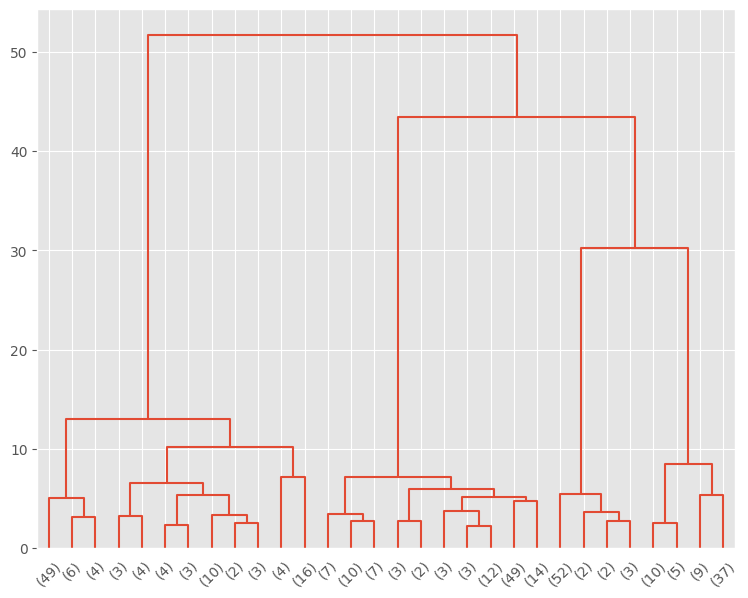

In [ ]:
fig = plt.figure(figsize = (9, 7))
dn = dendrogram(link, color_threshold = -1, truncate_mode = 'lastp', labels = df.index.tolist())

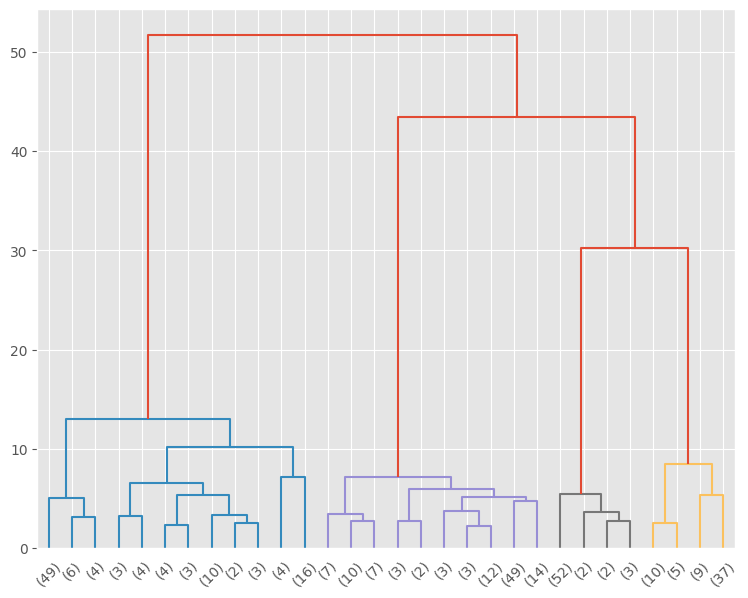

In [ ]:
fig = plt.figure(figsize=(9, 7))
dn = dendrogram(link, color_threshold = 20, truncate_mode = 'lastp', labels=df.index.tolist())

**Построение каменистой осыпи**

In [ ]:
dist = link[:, 2]
dist

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.  

Text(0, 0.5, 'Расстояние')

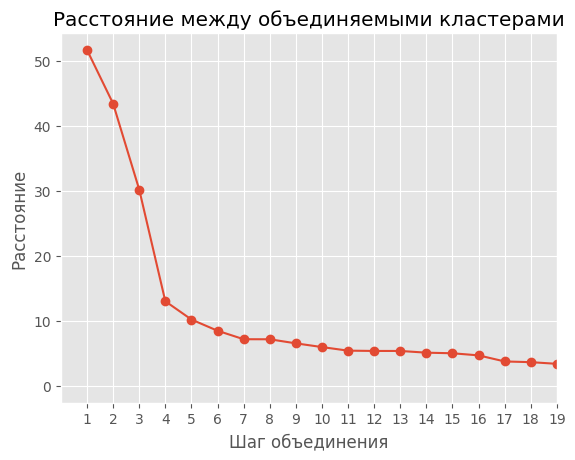

In [ ]:
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.xlim(0, 19)
plt.xticks(range(1, 20))
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

График каменистой осыпи подтвержает наличие 4 кластеров. Точка перегиба приходится в точке 4, происходит резкий скачок в расстоянии при переходе к 3 кластерам.

In [ ]:
df['cluster'] = fcluster(link, 4, criterion = 'maxclust')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,cluster
0,4,5,5,5,3,3,3,3,3,3,3,2
1,5,4,5,5,3,3,3,3,3,3,3,2
2,5,5,4,5,3,3,3,3,3,3,3,2
3,5,4,5,5,3,3,3,3,3,3,3,2
4,4,5,5,5,3,3,3,3,3,3,3,2


In [ ]:
df.groupby('cluster').size()

,0
cluster,
1,108
2,110
3,59
4,61


В целом кластеры распределены более менее равномерно, нет маленьких сегментов.

Нумерация кластеров соответствует их расположению на графике дендограммы слева направо.

In [ ]:
df.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


Кластер 1 (108 человек, 32%) - потребители приобретают леденцы для здоровья.

Кластер 2 (110 человек, 32.5%) - потребители приобретают леденцы для уверенности и свежести дыхания в полости рта.

Кластер 3 (59 человек, 17.5%) - потребители приобретают леденцы для концентрации

Кластер 4 (61 человек, 18%) - потребители приобретают ленедцы, так как они им нравятся как сладость

V1: Я потребляю леденцы, чтобы освежить дыхание

V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

V3: Я потребляю леденцы, чтобы освежить полость рта

V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

V5: Я потребляю леденцы как заменитель других кондитерских изделий

V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

V7: Леденцы помогают мне сконцентрироваться

V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

V11: Я потребляю леденцы для улучшения самочувствия

Вывод:

Покупатели леденцов делятся на 4 кластера.

Больше всего выручки идет от потребителей, которые приобретают леденцы для медицинских целей и дыхания рта. Следовательно, стоит приоритизировать продажу леденцов в аптеках, делать акцент на то, что леденцы помогает от болей в горле и продвигать леденцы с лимонным и мятным вкусом.

17.5% и 18% идут от потребителей, покупающих леденцы для концентрации и от любителей сладкого соответственно. Для первых можно продавать продукт в вендинговых автоматах, рядом с коворкингами в зонах отдыха, а для вторых расширять ассортимент (различные фруктовые, ягодные вкусы).